In [17]:
import kagglehub

path = kagglehub.dataset_download("crawford/gene-expression")
print(path)

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 1.41M/1.41M [00:00<00:00, 1.94MB/s]

Extracting files...
C:\Users\zehra\.cache\kagglehub\datasets\crawford\gene-expression\versions\3


In [18]:
from pathlib import Path

files = list(Path(path).rglob("*"))

for file in files:
    if file.is_file():
        print(file.name, "—", file.stat().st_size, "bytes")

actual.csv — 511 bytes
data_set_ALL_AML_independent.csv — 1860352 bytes
data_set_ALL_AML_train.csv — 2039681 bytes


In [19]:
import pandas as pd

data_path = Path(path)

train = pd.read_csv(data_path / "data_set_ALL_AML_train.csv")
test = pd.read_csv(data_path / "data_set_ALL_AML_independent.csv")
actual = pd.read_csv(data_path / "actual.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Labels:", actual.shape)

print("\nTrain columns:", train.columns[:10].tolist())
print("\nLabels preview:")
print(actual.head())

Train: (7129, 78)
Test: (7129, 70)
Labels: (72, 2)

Train columns: ['Gene Description', 'Gene Accession Number', '1', 'call', '2', 'call.1', '3', 'call.2', '4', 'call.3']

Labels preview:
   patient cancer
0        1    ALL
1        2    ALL
2        3    ALL
3        4    ALL
4        5    ALL


In [20]:
train_patients = [col for col in train.columns if col.isdigit()]
test_patients = [col for col in test.columns if col.isdigit()]

print("Training patients:", len(train_patients))
print("Test patients:", len(test_patients))

print("Train IDs:", train_patients)
print("Test IDs:", test_patients)

Training patients: 38
Test patients: 34
Train IDs: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '34', '35', '36', '37', '38', '28', '29', '30', '31', '32', '33']
Test IDs: ['39', '40', '42', '47', '48', '49', '41', '43', '44', '45', '46', '70', '71', '72', '68', '69', '67', '55', '56', '59', '52', '53', '51', '50', '54', '57', '58', '60', '61', '65', '66', '63', '64', '62']


In [ ]:
# Keep expression columns only
train_expr = train[train_patients].T
test_expr = test[test_patients].T


In [22]:
# Patient IDs as integers
train_expr.index = train_expr.index.astype(int)
test_expr.index = test_expr.index.astype(int)

In [23]:
# Encode ALL = 1, AML = 0
actual["cancer"] = actual["cancer"].map({"ALL": 1, "AML": 0})

In [24]:
# Attach labels using patient IDs
train_expr["target"] = actual.set_index("patient").loc[train_expr.index, "cancer"]
test_expr["target"] = actual.set_index("patient").loc[test_expr.index, "cancer"]

print("Train:", train_expr.shape)
print("Test:", test_expr.shape)
print("Train labels:", train_expr["target"].value_counts())
print("Test labels:", test_expr["target"].value_counts())

Train: (38, 7130)
Test: (34, 7130)
Train labels: target
1    27
0    11
Name: count, dtype: int64
Test labels: target
1    20
0    14
Name: count, dtype: int64


In [27]:
import numpy as np

X_train = train_expr.drop(columns="target")

print("Missing values in training data:", X_train.isna().sum().sum())
print("Infinite values in training data:",np.isinf(X_train.to_numpy(dtype=float)).sum())
print("Duplicate samples:", X_train.duplicated().sum())
print("Constant features:", (X_train.nunique() <= 1).sum())

Missing values in training data: 0
Infinite values in training data: 0
Duplicate samples: 0
Constant features: 0


In [28]:
print("Negative values:", (X_train < 0).sum().sum())
print("Zero values:", (X_train == 0).sum().sum())

print("Minimum:", X_train.min().min())
print("Maximum:", X_train.max().max())
print("Mean:", X_train.to_numpy().mean())
print("Median:", X_train.stack().median())

Negative values: 77175
Zero values: 738
Minimum: -28400
Maximum: 61228
Mean: 637.6980014913142
Median: 127.0


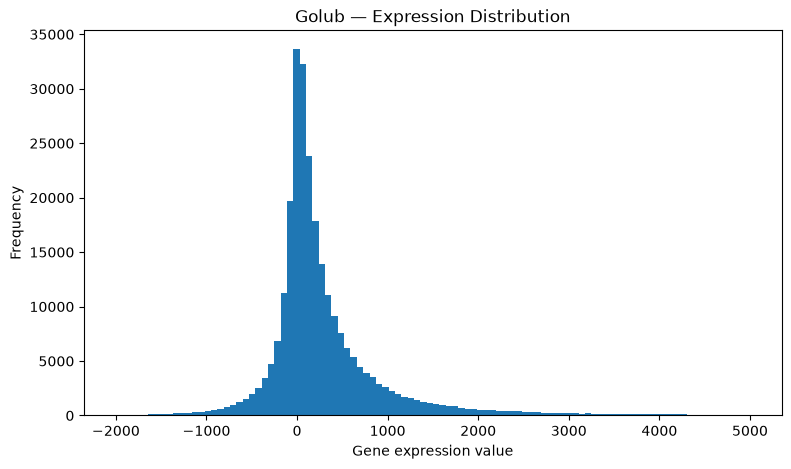

In [65]:
import matplotlib.pyplot as plt

values = X_train.to_numpy().flatten()

plt.figure(figsize=(9, 5))
plt.hist(values, bins=100, range=(-2000, 5000))
plt.xlabel("Gene expression value")
plt.ylabel("Frequency")
plt.title("Golub — Expression Distribution")
plt.show()

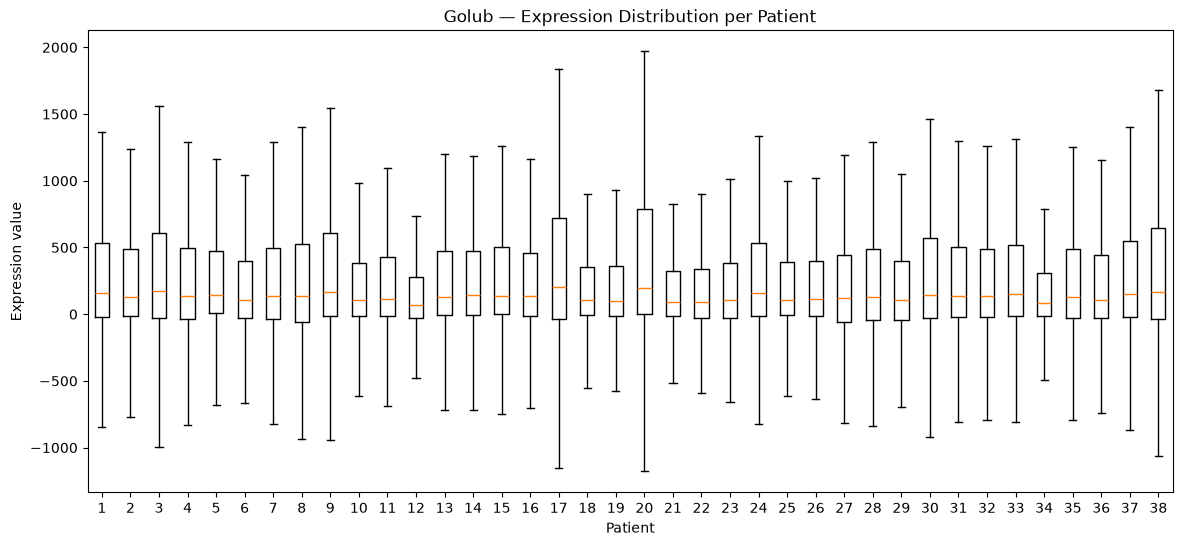

In [34]:
plt.figure(figsize=(14, 6))
plt.boxplot(X_train.T, showfliers=False)
plt.xlabel("Patient")
plt.ylabel("Expression value")
plt.title("Golub — Expression Distribution per Patient")
plt.show()

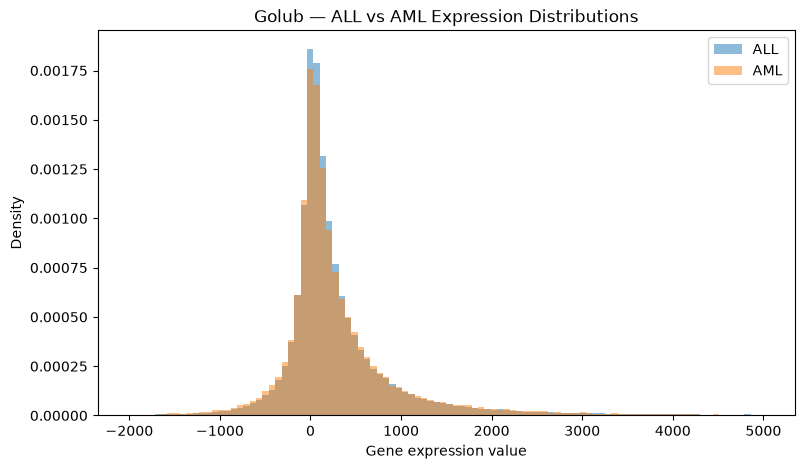

In [37]:
all_values = X_train.loc[train_expr["target"] == 1].to_numpy().flatten()
aml_values = X_train.loc[train_expr["target"] == 0].to_numpy().flatten()

plt.figure(figsize=(9, 5))

plt.hist(all_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="ALL")

plt.hist(aml_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="AML")

plt.xlabel("Gene expression value")
plt.ylabel("Density")
plt.title("Golub — ALL vs AML Expression Distributions")
plt.legend()
plt.show()

In [38]:
gene_variances = X_train.var(axis=0)

print(gene_variances.describe())
print(gene_variances.nlargest(10))

count    7.129000e+03
mean     6.820928e+05
std      3.845060e+06
min      4.769018e+02
25%      8.210373e+03
50%      3.170128e+04
75%      1.295735e+05
max      1.609285e+08
dtype: float64
5709    1.609285e+08
5647    9.014333e+07
5506    6.822979e+07
6605    6.455910e+07
5710    6.425958e+07
18      5.694293e+07
5715    5.456498e+07
4016    4.963480e+07
5228    4.168747e+07
41      4.010845e+07
dtype: float64


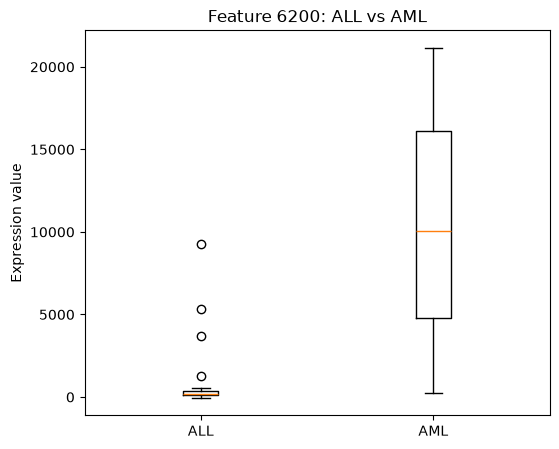

In [43]:
gene = 6200

all_expr = X_train.loc[train_expr["target"] == 1, gene]
aml_expr = X_train.loc[train_expr["target"] == 0, gene]

plt.figure(figsize=(6, 5))
plt.boxplot([all_expr, aml_expr], tick_labels=["ALL", "AML"])
plt.ylabel("Expression value")
plt.title(f"Feature {gene}: ALL vs AML")
plt.show()

In [ ]:
all_means = X_train.loc[train_expr["target"] == 1].mean(axis=0)
aml_means = X_train.loc[train_expr["target"] == 0].mean(axis=0)

mean_differences = (all_means - aml_means).abs()

print(mean_differences.nlargest(20))

6200    9604.686869
1673    8952.720539
2185    7711.875421
1881    7279.101010
1375    6606.117845
2401    6546.434343
1393    6159.313131
6199    5943.760943
6802    5600.602694
4935    5531.602694
dtype: float64


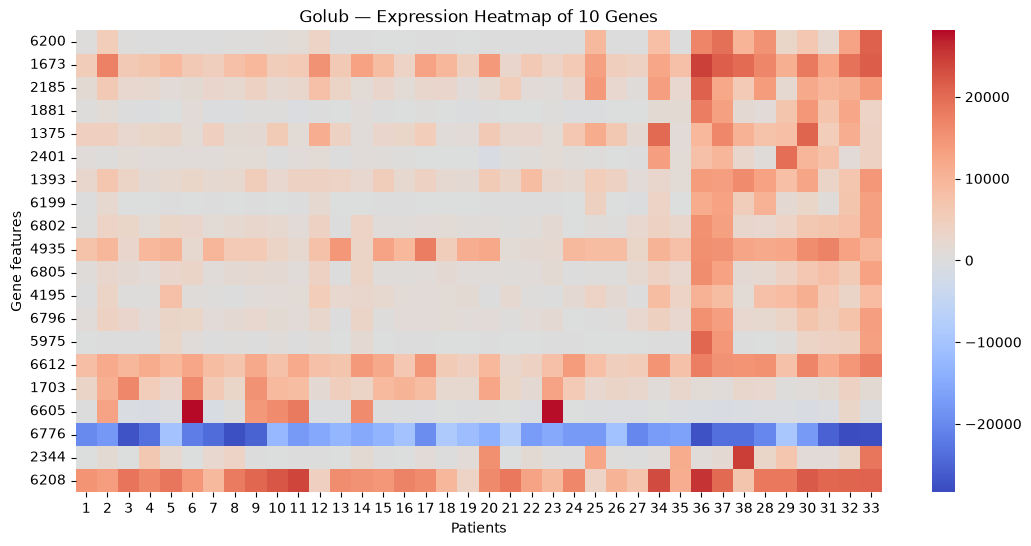

In [66]:
import seaborn as sns

top_genes = mean_differences.nlargest(20).index

heatmap_data = X_train[top_genes].T
plt.figure(figsize=(13, 6))

sns.heatmap(
heatmap_data, cmap="coolwarm", center=0
)

plt.xlabel("Patients")
plt.ylabel("Gene features")
plt.title("Golub — Expression Heatmap of 10 Genes")
plt.show()

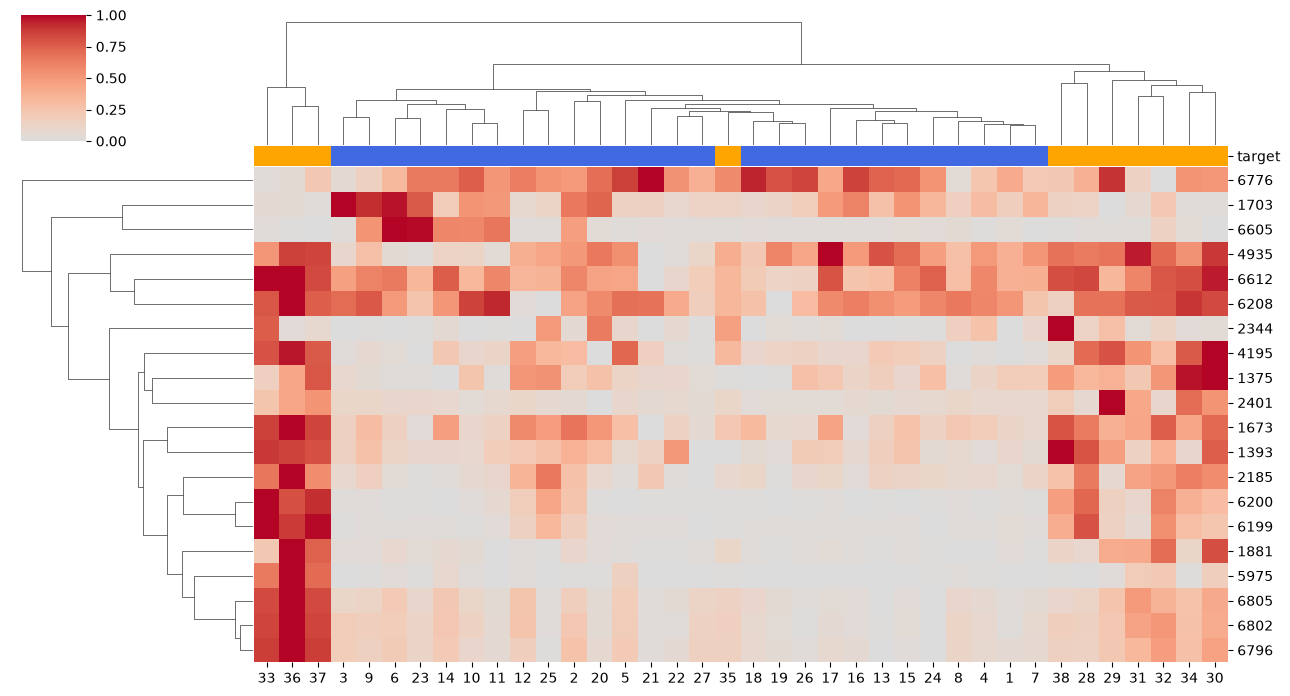

In [61]:
patient_colors = train_expr["target"].map({
    1: "royalblue",
    0: "orange"
})

sns.clustermap(
    heatmap_data,
    cmap="coolwarm",
    center=0,
    standard_scale=0,
    col_colors=patient_colors.loc[heatmap_data.columns],
    figsize=(13, 7)
)

plt.show()

In [59]:
X_train_log = np.sign(X_train) * np.log2(1 + np.abs(X_train))

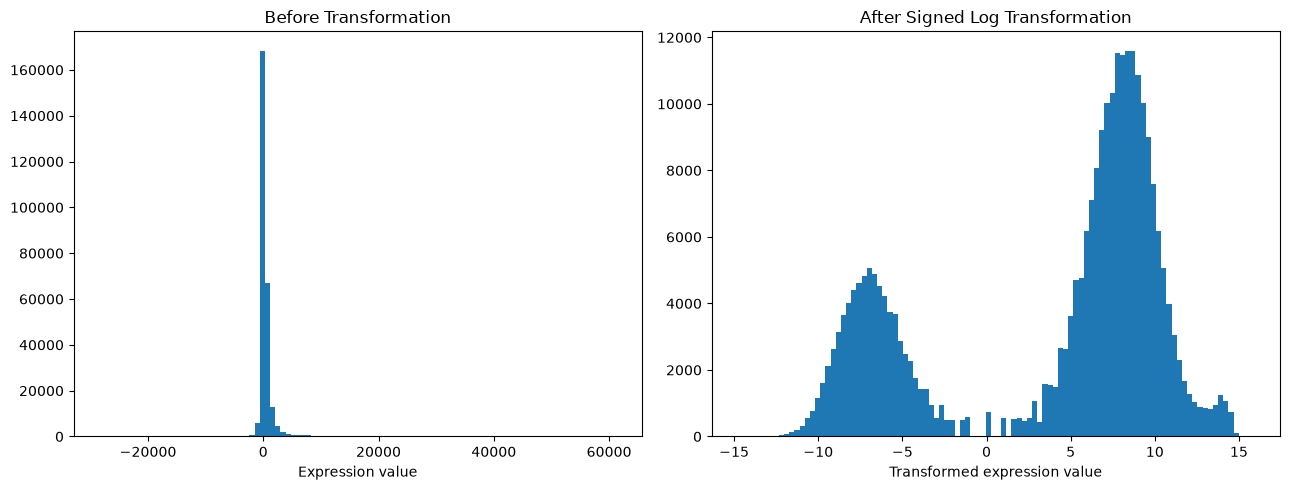

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(X_train.to_numpy().flatten(), bins=100)
axes[0].set_title("Before Transformation")
axes[0].set_xlabel("Expression value")

axes[1].hist(X_train_log.to_numpy().flatten(), bins=100)
axes[1].set_title("After Signed Log Transformation")
axes[1].set_xlabel("Transformed expression value")

plt.tight_layout()
plt.show()

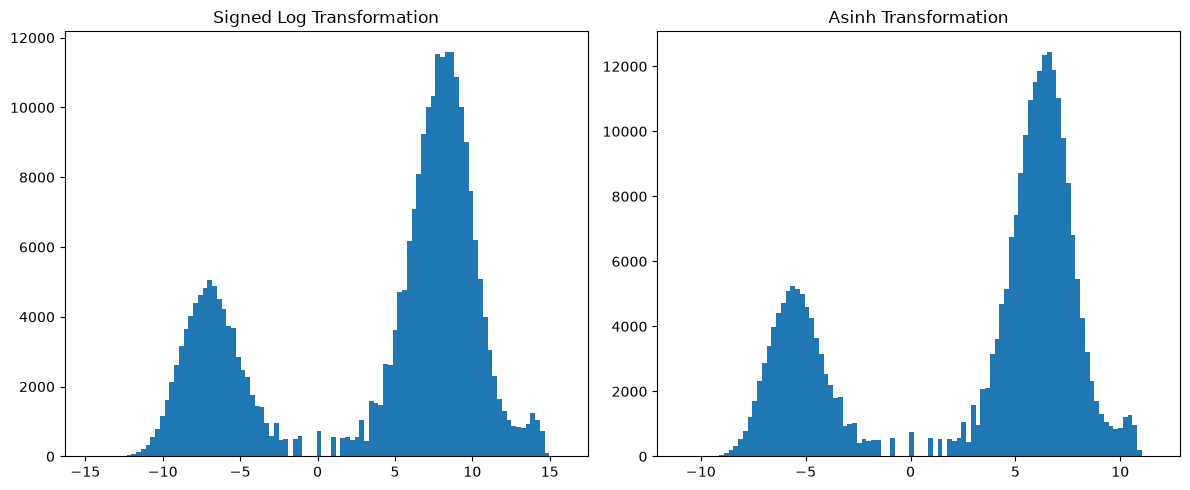

In [63]:
X_train_asinh = np.arcsinh(X_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(X_train_log.to_numpy().ravel(), bins=100)
axes[0].set_title("Signed Log Transformation")

axes[1].hist(X_train_asinh.to_numpy().ravel(), bins=100)
axes[1].set_title("Asinh Transformation")

plt.tight_layout()
plt.show()

In [67]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

In [68]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [69]:
print(X_pca.shape)
print(pca.explained_variance_ratio_)

(38, 2)
[0.14987793 0.11977811]


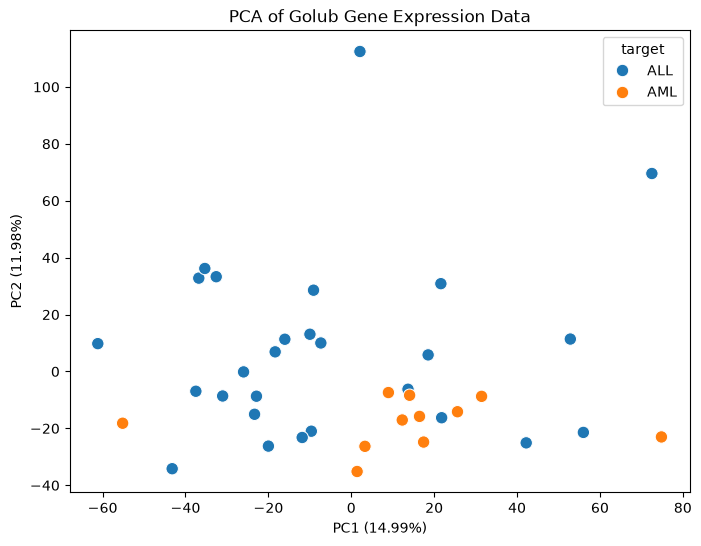

In [70]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=train_expr["target"].map({1: "ALL", 0: "AML"}),
    s=80
)

plt.xlabel("PC1 (14.99%)")
plt.ylabel("PC2 (11.98%)")
plt.title("PCA of Golub Gene Expression Data")
plt.show()